In [1]:
from pathlib import Path
import pandas as pd

file_path = Path("data") / "headbrain.csv"
df = pd.read_csv(file_path)

print("ابعاد داده:", df.shape)
display(df.head())
display(df.tail())
df.info()


ابعاد داده: (237, 4)


,Gender,Age Range,Head Size(cm^3),Brain Weight(grams)
0,1,1,4512,1530
1,1,1,3738,1297
2,1,1,4261,1335
3,1,1,3777,1282
4,1,1,4177,1590


,Gender,Age Range,Head Size(cm^3),Brain Weight(grams)
232,2,2,3214,1110
233,2,2,3394,1215
234,2,2,3233,1104
235,2,2,3352,1170
236,2,2,3391,1120


<class 'pandas.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Gender               237 non-null    int64
 1   Age Range            237 non-null    int64
 2   Head Size(cm^3)      237 non-null    int64
 3   Brain Weight(grams)  237 non-null    int64
dtypes: int64(4)
memory usage: 7.5 KB


In [2]:
print("نام ستون‌ها:")
print(df.columns.tolist())

print("\nمقادیر گمشده در هر ستون:")
print(df.isnull().sum())

print("\nتعداد ردیف‌های تکراری:")
print(df.duplicated().sum())

print("\nآمار توصیفی:")
display(df.describe())


نام ستون‌ها:
['Gender', 'Age Range', 'Head Size(cm^3)', 'Brain Weight(grams)']

مقادیر گمشده در هر ستون:
Gender                 0
Age Range              0
Head Size(cm^3)        0
Brain Weight(grams)    0
dtype: int64

تعداد ردیف‌های تکراری:
0

آمار توصیفی:


,Gender,Age Range,Head Size(cm^3),Brain Weight(grams)
count,237.000000,237.000000,237.000000,237.000000
mean,1.434599,1.535865,3633.991561,1282.873418
std,0.496753,0.499768,365.261422,120.340446
min,1.000000,1.000000,2720.000000,955.000000
25%,1.000000,1.000000,3389.000000,1207.000000
50%,1.000000,2.000000,3614.000000,1280.000000
75%,2.000000,2.000000,3876.000000,1350.000000
max,2.000000,2.000000,4747.000000,1635.000000


In [3]:
print("نام ستون‌ها:")
print(df.columns.tolist())

print("\nمقادیر گمشده در هر ستون:")
print(df.isnull().sum())

print("\nتعداد ردیف‌های تکراری:")
print(df.duplicated().sum())

print("\nتعداد نمونه‌ها در هر کد جنسیت:")
print(df["Gender"].value_counts().sort_index())

print("\nتعداد نمونه‌ها در هر گروه سنی:")
print(df["Age Range"].value_counts().sort_index())


نام ستون‌ها:
['Gender', 'Age Range', 'Head Size(cm^3)', 'Brain Weight(grams)']

مقادیر گمشده در هر ستون:
Gender                 0
Age Range              0
Head Size(cm^3)        0
Brain Weight(grams)    0
dtype: int64

تعداد ردیف‌های تکراری:
0

تعداد نمونه‌ها در هر کد جنسیت:
Gender
1    134
2    103
Name: count, dtype: int64

تعداد نمونه‌ها در هر گروه سنی:
Age Range
1    110
2    127
Name: count, dtype: int64


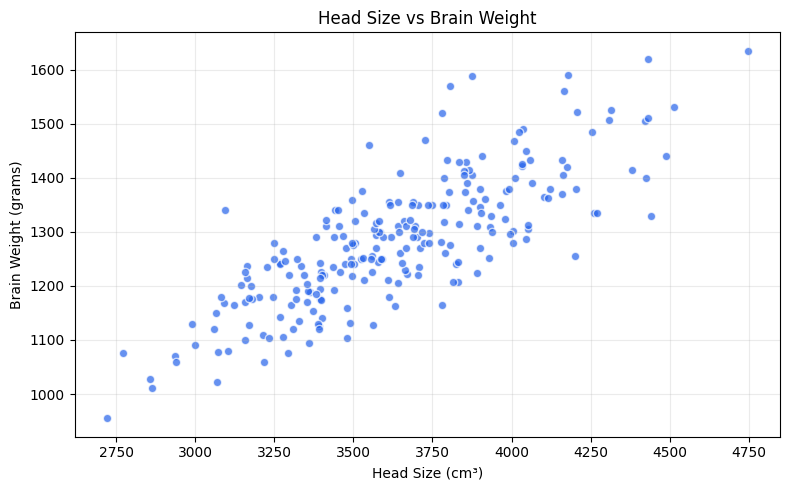

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt

head_size = "Head Size(cm^3)"
brain_weight = "Brain Weight(grams)"

Path("images").mkdir(exist_ok=True)

plt.figure(figsize=(8, 5))
plt.scatter(
    df[head_size],
    df[brain_weight],
    alpha=0.7,
    color="#2563EB",
    edgecolor="white"
)

plt.title("Head Size vs Brain Weight")
plt.xlabel("Head Size (cm³)")
plt.ylabel("Brain Weight (grams)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("images/head_size_vs_brain_weight.png", dpi=150, bbox_inches="tight")
plt.show()


In [5]:
correlation = df["Head Size(cm^3)"].corr(
    df["Brain Weight(grams)"]
)

print(f"همبستگی اندازهٔ سر و وزن مغز: {correlation:.3f}")


همبستگی اندازهٔ سر و وزن مغز: 0.800


In [6]:
print("میانگین وزن مغز بر اساس Gender:")
print(
    df.groupby("Gender")["Brain Weight(grams)"]
      .agg(["count", "mean", "std"])
      .round(2)
)

print("\nمیانگین وزن مغز بر اساس Age Range:")
print(
    df.groupby("Age Range")["Brain Weight(grams)"]
      .agg(["count", "mean", "std"])
      .round(2)
)


میانگین وزن مغز بر اساس Gender:
        count     mean     std
Gender                        
1         134  1331.86  108.93
2         103  1219.15  103.83

میانگین وزن مغز بر اساس Age Range:
           count     mean     std
Age Range                        
1            110  1304.74  116.41
2            127  1263.94  120.93


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

target = "Brain Weight(grams)"

# دو مجموعه ویژگی برای مقایسه
feature_sets = {
    "فقط اندازه سر": ["Head Size(cm^3)"],
    "اندازه سر + جنسیت + گروه سنی": [
        "Head Size(cm^3)",
        "Gender",
        "Age Range",
    ],
}

# تقسیم یکسان برای هر دو مدل
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42
)

results = []

for model_name, features in feature_sets.items():
    X_train = df.loc[train_idx, features]
    X_test = df.loc[test_idx, features]
    y_train = df.loc[train_idx, target]
    y_test = df.loc[test_idx, target]

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "مدل": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R²": r2_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).round(2)
results_df


,مدل,MAE,RMSE,R²
0,فقط اندازه سر,54.63,68.35,0.71
1,اندازه سر + جنسیت + گروه سنی,54.09,65.95,0.73


In [8]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
import pandas as pd

X = df[[
    "Head Size(cm^3)",
    "Gender",
    "Age Range",
]]
y = df["Brain Weight(grams)"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

model = LinearRegression()

scores = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2",
    },
)

cv_results = pd.DataFrame({
    "MAE": -scores["test_MAE"],
    "RMSE": -scores["test_RMSE"],
    "R²": scores["test_R2"],
})

print("نتایج هر بخش:")
display(cv_results.round(2))

print("\nمیانگین معیارها:")
display(cv_results.mean().to_frame("میانگین").round(2))

print("\nانحراف معیار معیارها:")
display(cv_results.std().to_frame("انحراف معیار").round(2))


نتایج هر بخش:


,MAE,RMSE,R²
0,54.09,65.95,0.73
1,56.11,68.05,0.59
2,61.57,76.01,0.64
3,52.60,70.02,0.65
4,55.97,77.38,0.56



میانگین معیارها:


,میانگین
MAE,56.07
RMSE,71.48
R²,0.63



انحراف معیار معیارها:


,انحراف معیار
MAE,3.40
RMSE,4.99
R²,0.07


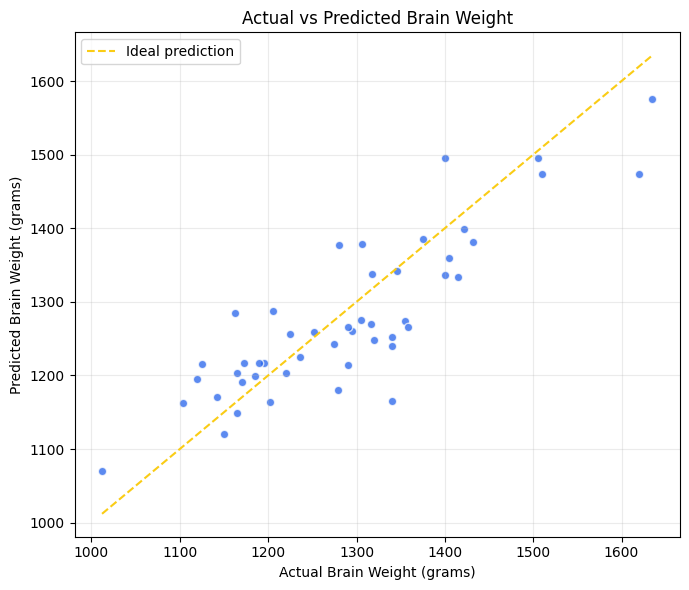

In [9]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from pathlib import Path

features = [
    "Head Size(cm^3)",
    "Gender",
    "Age Range",
]
target = "Brain Weight(grams)"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Path("images").mkdir(exist_ok=True)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.75, color="#2563EB", edgecolor="white")

# خط ایده‌آل: پیش‌بینی = مقدار واقعی
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "--", color="#FACC15", label="Ideal prediction")

plt.xlabel("Actual Brain Weight (grams)")
plt.ylabel("Predicted Brain Weight (grams)")
plt.title("Actual vs Predicted Brain Weight")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
import pandas as pd

# مقایسهٔ مقدار واقعی و پیش‌بینی‌شده در داده‌های آزمون
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute Error"] = results["Error"].abs()

results.head(10)


,Actual,Predicted,Error,Absolute Error
115,1275,1242.289949,32.710051,32.710051
15,1405,1359.424397,45.575603,45.575603
211,1320,1247.924765,72.075235,72.075235
126,1125,1215.510573,-90.510573,90.510573
6,1400,1336.860292,63.139708,63.139708
170,1202,1163.717975,38.282025,38.282025
9,1375,1385.707859,-10.707859,10.707859
221,1012,1070.387418,-58.387418,58.387418
112,1295,1260.142867,34.857133,34.857133
220,1185,1198.581284,-13.581284,13.581284


In [11]:
results.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)


,Actual,Predicted,Error,Absolute Error
18,1340,1165.769832,174.230168,174.230168
109,1620,1473.138092,146.861908,146.861908
186,1163,1284.473126,-121.473126,121.473126
148,1340,1239.592874,100.407126,100.407126
82,1279,1180.300652,98.699348,98.699348
182,1280,1376.961157,-96.961157,96.961157
19,1400,1495.304936,-95.304936,95.304936
16,1358,1265.448622,92.551378,92.551378
126,1125,1215.510573,-90.510573,90.510573
10,1340,1252.058934,87.941066,87.941066


In [12]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
import joblib

# 1. آموزش مدل روی کل داده‌های X و y
final_model = LinearRegression()
final_model.fit(X, y)

# 2. ذخیرهٔ مدل در فایل
joblib.dump(final_model, "head_brain_model.joblib")

print("✅ مدل با موفقیت در فایل head_brain_model.joblib ذخیره شد.")


✅ مدل با موفقیت در فایل head_brain_model.joblib ذخیره شد.


In [16]:
import flet as ft
import joblib
import sklearn

print("Flet version:", getattr(ft, "__version__", "Installed"))
print("scikit-learn version:", sklearn.__version__)

model = joblib.load("head_brain_model.joblib")
print("Model:", model)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Features:", getattr(model, "feature_names_in_", "no feature names stored"))


Flet version: 1.0.1
scikit-learn version: 1.8.0
Model: LinearRegression()
Coefficients: [  0.24421175 -22.5432537  -23.96844543]
Intercept: 464.5628108857368
Features: ['Head Size(cm^3)' 'Gender' 'Age Range']
